# Micrograd

##### Micrograd is an automatic gradient(Autograd) engine that impliments backpropagation.
##### Backpropagation is an algorithm that efficiently evaluate the gradient of a loss function with respect to the weights of a neural network. 
##### By doing this we can iteratively reduce the loss function and improve the accuracy.

### Understanding Derivative 

In [1]:
import math 
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline 

In [2]:
# define the scalar valued function
def f(x):
    return 3*x**2 - 4*x +5
    

In [3]:
f(3.0)

20.0

In [4]:
# Create a set of scalar values to evaluate the function from -5 to 5 with a step size of 0.25. 5 is not included in the range.
xs = np.arange(-5,5,0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [5]:
# Call the function on the numpy array of scalar values to get the corresponding function values.
ys = f(xs)
ys 

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

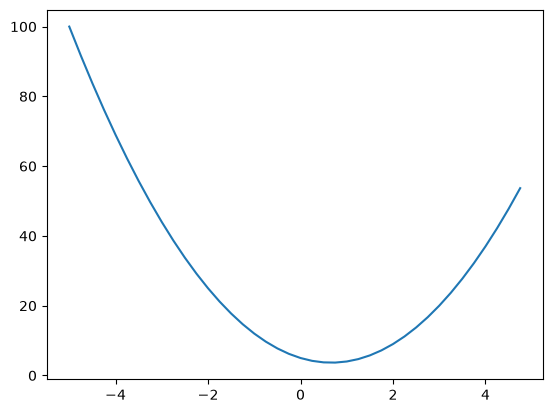

In [6]:
# Plot the results using matplotlib
plt.plot(xs,ys)

##### The next step is to check what is the derivative of the function at different points of x 

##### The formula used for reference is 
https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/karpathy1_ref_img1.png

In [7]:
h = 0.001
x = 3.0
# This shows if we slightly change the value of x in a positive direction how is the function going to respond 
f(x+h)


20.014003000000002

In [8]:
# Now check how much the function responded to the change in x in a positive direction
f(x+h) - f(x)

0.01400300000000243

In [9]:
# Normalise the results by the run to get the slope 
(f(x+h) - f(x)) / h

# To converge to the right answer we need to make the value of h very small.

14.00300000000243

### To check if the answer is corret 

https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/karpathy1_ref_img2.jpg



In [10]:
# check what would be the result if x = -3 
h = 0.000000001
x = -3.0
(f(x+h) - f(x)) / h

-22.000001820288162

In [11]:
# Try to find out the point at which the slope is 0 
h = 0.000000001
x = 2/3
(f(x+h) - f(x)) / h

0.0

### A bit more complex case for understanding derivatives 

In [12]:
a = 2.0
b = -3.0
c = 10.0
# d is the outpu of 3 scalar inputs a,b and c
d = a*b + c
print(d)

4.0


In [13]:
# evaluate the derivative of the function d and understand the slope of the function at a given point use the following steps 

h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to a
a += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to a
# here d2-d1 is how much the function increased when we increased the value of a by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)

# the value of the function will go down because b is a negative number. So the slope is negative.



d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [14]:
# Now evaluate the derivative of the function d with respect to b and understand the slope of the function at a given point use the following steps
h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to b
b += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to b
# here d2-d1 is how much the function increased when we increased the value of a by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)


d1 4.0
d2 4.0002
slope 2.0000000000042206


In [15]:
# Now evaluate the derivative of the function d with respect to c and understand the slope of the function at a given point use the following steps
h = 0.0001

#inputs 
a = 2.0
b = -3.0
c = 10.0


d1 = a*b + c

# derivative of d with respect to c
c += h
d2 = a*b + c

# print the results 

print('d1', d1)
print('d2', d2)

# print the derivative or slope of the function d with respect to c
# here d2-d1 is how much the function increased when we increased the value of c by h.This value is normalised by h. So the slope is (d2-d1)/h
print('slope', (d2-d1)/h)


d1 4.0
d2 4.0001
slope 0.9999999999976694


## Single Value Objects 

Here we are trying to build a neural network engine from scratch. To train a neural network python needs top know all web of maths and gradients behind it. 


In [16]:
# Value is a custom container that is built around a scalar value.This contains the data. 
class Value:
    def __init__(self,data):
        self.data = data

    def __repr__(self):
        return f"Value(data={self.data})"

In [17]:
a= Value(2.0)
a

Value(data=2.0)

In [18]:
print(type(a))

<class '__main__.Value'>


In [19]:
b = Value(-3.0)
b

Value(data=-3.0)

In [20]:
# Now this will give an error because  python dosent know how to add two Value objects. We need to define the addition operation for the Value class.
# a + b


---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
Cell In[23], line 1
----> 1 a + b

TypeError: unsupported operand type(s) for +: 'Value' and 'Value'

In [21]:
# Now the add function will be added to the value class to define how two Value objects can be added together. This is done by defining the __add__ method in the Value class.

class Value:
    def __init__(self,data):
        self.data = data

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

In [22]:
# This will now add a and b by doing a.__add__(b) which is the same as a + b. This will return a new Value object with the data being the sum of the data of a and b.
a = Value(2.0)
b = Value(-3.0)
a + b

Value(data=-1.0)

In [23]:
# To improve the performance now we will be adding the multiplication operation to the value class.

class Value:
    def __init__(self,data):
        self.data = data
    # the __repr__ function will return the string representation of the Value object. 
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data)
        return out

In [24]:
# we can now check how the multiplication works .
a = Value(2.0)
b = Value(-3.0)
a*b

Value(data=-6.0)

In [25]:
# now we can add c to the product of a and b. this will be working like  (a.__mul__(b)).__add__(c) which is the same as a*b + c. 
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
a*b + c

Value(data=4.0)

In [26]:
d = a*b + c
d

Value(data=4.0)

In [27]:
# The next step is createing a connected track of which values are produced by which other values. 
# This is done by adding a list of children to the Value class. 
# Each Value object will have a list of its children, which are the Value objects that were used to create it. 
# This will allow us to traverse the graph of Value objects and compute gradients using backpropagation.

class Value:
    def __init__(self,data, _children=()):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other))
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other))
        return out

In [28]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c
d

Value(data=4.0)

In [29]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [30]:
# From the results we know the children of d are a*b = -6.0 and c = 10.0 however we are not sure about what is the operation that was used to create d from its children. 
# To keep track of this we will add a _op attribute to the Value class. This will store the operation that was used to create the Value object.

class Value:
    def __init__(self,data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c
d



Value(data=4.0)

In [31]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [32]:
d._op

' +'

In [33]:
# Now lets label the inputs and then visualise the graph of Value objects using graphviz. 
# This will help us understand how the Value objects are connected and how the operations are performed.


class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
d



Value(data=4.0)

In [34]:
from graphviz import Digraph

def trace(root):
    # This function will traverse the graph of Value objects and return a set of all the Value objects in the graph.
    # build a set of all the Value objects in the graph by traversing the graph using depth first search.
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # This function will draw the graph of Value objects using graphviz.
    dot = Digraph(format='svg', graph_attr={'rankdir': 'TB'}) # create a new Digraph object with left to right layout, LR means left to right. TB means top to bottom.
    nodes, edges = trace(root) # get the nodes and edges of the graph
    for n in nodes:
        uid = str(id(n)) # get the unique id of the node
        # for any node n, we will create a record shape with the label being the label of the node and the data of the node. 
        # The label will be in the format of {label | data}. The shape will be a record shape which is a rectangle with a horizontal line in the middle. 
        # The top half will contain the label and the bottom half will contain the data.
        dot.node(name=uid, label="{ %s | data %.4f }" % (n.label, n.data), shape='record') # add the node to the graph
        if n._op:
            # if this value is a result of an operation, add a node for the operation and connect it to the value node. 
            # The operation node will be a circle with the label being the operation.
            dot.node(name=uid + n._op, label=n._op, shape='circle') # add the operation to the graph
            dot.edge(uid + n._op, uid) # add an edge from the operation to the node
    for n1, n2 in edges:
        # for each edge in the graph, add an edge from the child to the parent. 
        # The edge will be from the child node to the operation node and then from the operation node to the parent node.
        dot.edge(str(id(n1)), str(id(n2)) + n2._op) # add an edge from the child to the parent
    return dot

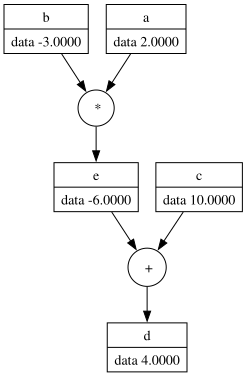

In [35]:
draw_dot(d)

In [36]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L =  d * f ; L.label='L'
L

Value(data=-8.0)

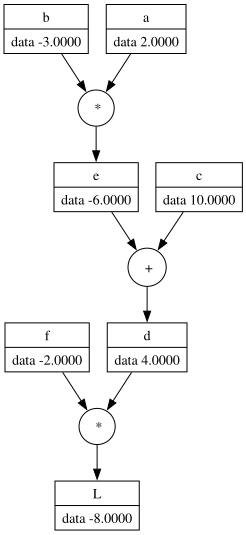

In [37]:
draw_dot(L)

## Backpropagation

##### Now that we have built the graph, the next step is to start with the back propagation.
##### In this we start at the end and revesre and calculate the gradient along all the values(f,d,e,c,b,a)
##### Compute the derivative of the value with respect to L. for example derivative of e with respect to L
##### This derivative variable will be called as grad




#### Note: 

##### a,b are inputs that can be called as weights
##### c,d,e are intermediate notdes 
##### L is the loss or the error value that is trying to minimise 
##### h is a tiny nudge temporarily use to test the slope 


In [38]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L =  d * f ; L.label='L'
L

Value(data=-8.0)

In [39]:
from graphviz import Digraph

def trace(root):
    # This function will traverse the graph of Value objects and return a set of all the Value objects in the graph.
    # build a set of all the Value objects in the graph by traversing the graph using depth first search.
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # This function will draw the graph of Value objects using graphviz.
    dot = Digraph(format='svg', graph_attr={'rankdir': 'TB'}) # create a new Digraph object with left to right layout, LR means left to right. TB means top to bottom.
    nodes, edges = trace(root) # get the nodes and edges of the graph
    for n in nodes:
        uid = str(id(n)) # get the unique id of the node
        # for any node n, we will create a record shape with the label being the label of the node and the data of the node. 
        # The label will be in the format of {label | data}. The shape will be a record shape which is a rectangle with a horizontal line in the middle. 
        # The top half will contain the label and the bottom half will contain the data.
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record') # add the node to the graph
        if n._op:
            # if this value is a result of an operation, add a node for the operation and connect it to the value node. 
            # The operation node will be a circle with the label being the operation.
            dot.node(name=uid + n._op, label=n._op, shape='circle') # add the operation to the graph
            dot.edge(uid + n._op, uid) # add an edge from the operation to the node
    for n1, n2 in edges:
        # for each edge in the graph, add an edge from the child to the parent. 
        # The edge will be from the child node to the operation node and then from the operation node to the parent node.
        dot.edge(str(id(n1)), str(id(n2)) + n2._op) # add an edge from the child to the parent
    return dot

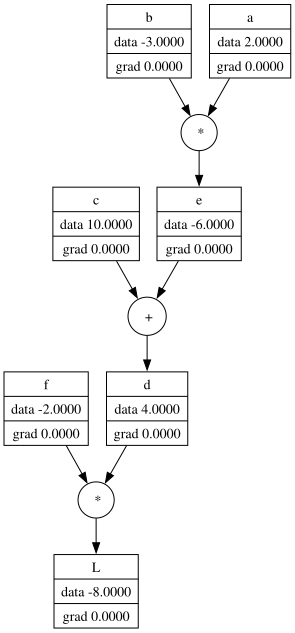

In [40]:
draw_dot(L)

##### In the first step the gradient of every input node, intermediate node and the output node are 0.0000
##### In the next step we begin with finding the gradient of L


In [41]:
type(L)

__main__.Value

### An example to check the derivative with repect to a, skip it for now if getting confused 

In [42]:
# Hre we are going to check the slope of the function L with respect to a,b,c and f. 
# This is done by slightly changing the value of a,b,c and f and checking how much the value of L changes. 
# This change in L is then normalised by the change in a,b,c and f to get the slope.

# Now to begin with we will check the slope of the function L with respect to a. 
# This is done by slightly changing the value of a and checking how much the value of L changes. 
# This change in L is then normalised by the change in a to get the slope.

# From the result it is clear that the slope of the function L with respect to a is -6.0.

def lol():

    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

6.000000000021544


## Starting backpropagation from L

In [43]:
# Now in the next step we change L by h and see what the derivative is 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data + h 

    print((L2-L1)/h)

lol()

1.000000000000334


#### The output above is can be explained as ((L+h)-L)/h = h/h = 1.0 
#### Also we know that the derivative of anything with respect to itself is 1 
#### So to find the gradient at the node L we have to derive L with respect to L and the result is 1.0 

#### From the above explanation we can manually set L.grad = 1.0

In [44]:
L.grad = 1.0

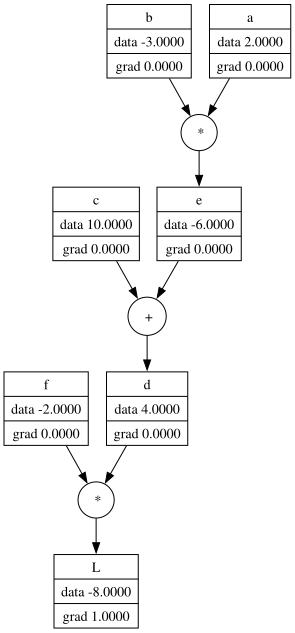

In [45]:
# Redraw the graph now
draw_dot(L)

## Back propagation on the next intermediate node d and f which is derivative of L with respect to d and f 

#### Now the next step is to check the derivative of L with respect to d and f 

#### We know that L = d*f 

#### To find the derivative of L with respect to d which is dL/dd
#### Now to manually calculate the dervative we can use the formula (f(x+h)-f(x))/h where limit h->0
#### f(x+h) = (d+h)*f. because we are finding the derivative with respect to d, we must add h directly to $d$ before the multiplication happens.
#### f(x) = d*f

#### So now the formula becomes 
#### ((d+h) * f - d * f)/h 
####  = (d * f) + (h * f) - (d*f)/h
####  = h*f / h
####  = f



#### So now we know that dL/dd  = f = -2.0000
#### simillerly  dL/df = d = 4.0000



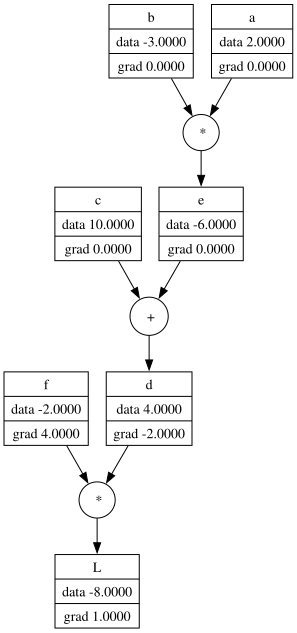

In [46]:
# now this can be added to the graph
f.grad = 4.0
d.grad = -2.0

draw_dot(L)


#### Now we have manually checked and updated the graph. However we check this on the code 

In [47]:
# check the derivative of L with respect to f , check the result which is almost 4 

def lol():

    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 + h, label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

3.9999999999995595


In [48]:
# check the derivative of L with respect to d 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    d.data += h
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()

-2.000000000000668


## Back propagation on the next intermediate node c and e , thet is derivative of L with respect to c and e 

##### To begin with we can now check the derivative of L with respect to c which is dL/dc
##### Now we need to know how does c impact L through d
##### Now to understand we need to know the impact of c is having on d and the impact of d is having on L and put these information together to get the impact of c on L 


##### Now we already know derivative of L with respect to d 
##### so the next step is to find derivative of d with respect to c or dd/dc 

##### d = c + e 

##### now we can use the definition of a derivative 
##### (f ( x + h ) - f ( x ) ) / h where limit h->0

##### f( x + h ) = c + h + e
##### f(x)   = c + e


##### (f ( x + h ) - f ( x ) ) / h  = ((c + h + e) - (c + e)) / h
#####                               = (c + h + e - c - e) / h
#####                               = h / h
#####                               = 1.0


##### simillerly dd/de = 1.0

### **Now the local derivatives are**

#####  dd/dc = 1.0
#####  dd/de = 1.0





### Chain Rule (Calculus)

#### To check the impact of C on  L we put the imformation together with the help of the chain rule in calculus 
#### Reference for chain rule is given in
#### 1. https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/chain_rule_equation_ref.png
#### 2. https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/chain_rule_example_problem.png

#### Our aim here is to calculate  dL / dc  which is the impact of c on L 
#### dL / dc = (dL / dd) * (dd / dc)
#### from the previous steps we know that 
#### dL / dd = -2.0000
#### dd / dc = 1.0
#### dL / dc = -2.0000 * 1.0 = -2.0000


#### Simillerly the impact of e on L can be calculated as 
#### dL / de = (dL / dd) * (dd / de) 
#### dL / dd = -2.0000
#### dd / de = 1.0
#### dL / de = -2.0000 * 1.0 = -2.0000

In [49]:
c.grad = -2.0
e.grad = -2.0

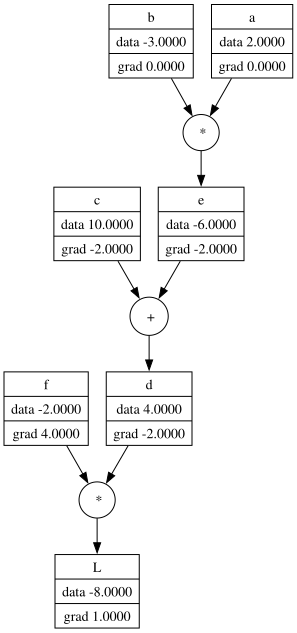

In [50]:
draw_dot(L)

In [51]:
# Now we check and varify the results for change of L with respect to c

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    c.data += h
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-1.9999999999988916


In [52]:
# Now we check and varify the results for change of L with respect to e

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    e.data += h
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-2.000000000000668


## Now as the last step we will be finding out the change of L with respect to a and b 

#### Here we again use the chain rule 

#### dL / da = (dL / de) * (de / da)
#### = ((dL / dd) * (dd / de)) *  (de / da)

#### Now we already know the value for (dL / dd) * (dd / de) = -2.0
#### The next step will be to find out the value of de / da

#### e = a * b 

#### use the formula (f(x+h)-f(x))/h where limit h->0

#### f(x+h) = ( a + h ) * b 
#### f(x) = a*b
#### (f(x+h)-f(x))/h = (( a + h ) * b  - a*b) / h
#### = ( a * b + h * b - a * b)/h
#### = h * b / h
#### = b 
#### = -3.0 = de / da

#### simillerly dL / db = a  = 2.0


#### dL / da = (dL / de) * (de / da) = -2.0 * -3.0
#### dL / db = (dL / de) * (de / db) = -2.0 * 2.0


In [53]:
a.grad = -2.0 * -3.0
b.grad = -2.0 * 2.0

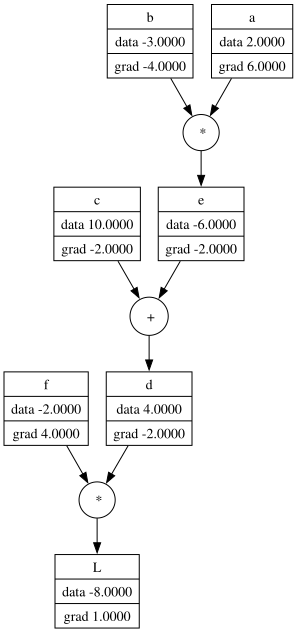

In [54]:
draw_dot(L)

In [55]:
# Now we can cross checkm the answers 
# Change of L with respect to a 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    a.data += h
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()




6.000000000000227


In [56]:
# Now we can cross checkm the answers 
# Change of L with respect to b 

def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L =  d * f ; L.label='L'
    L1 = L.data

    a = Value(2.0 , label='a')
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0 , label='f')
    L =  d * f ; L.label='L'
    L2 = L.data

    print((L2-L1)/h)

lol()


-3.9999999999995595


| Variable | Data (Forward Pass) | Grad (Backward Pass) | What the `.grad` means |
| :--- | :---: | :---: | :--- |
| **`a`** | `-4.0` | **`-6.0`** | If you increase `a` by a tiny bit, `d` will *decrease* by 6 times that amount. |
| **`b`** | `2.0` | **`-4.0`** | If you increase `b` by a tiny bit, `d` will *decrease* by 4 times that amount. |
| **`c`** | `-2.0` | **`-4.0`** | If you increase intermediate node `c` by a tiny bit, `d` will *decrease* by 4 times that amount. |
| **`d`** | `8.0` | **`1.0`** | The starting point of the backward pass (baseline sensitivity of the final output). |

## In the next step we can try to make L grow up by making changes in the direction of the gradient 

#### we make changes in the leaf nodes which have control over


In [57]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad


# rewrite the forward pass 

e = a * b
d = e + c
L = d * f

print(L.data)

-7.286496


### The gradient hands  two crucial pieces of information for every single variable in your code:

##### 1. The Sign (Plus or Minus): It tells you with 100% certainty whether increasing or decreasing that specific variable will push the final error down. You no longer have to guess.

##### 2. The Magnitude (The Size of the Number): It tells you how much leverage that variable has. If a gradient is huge, you know that tweaking that specific weight will have a massive impact on fixing your mistake.

## Backpropagation Example 2 - Backpropagate through neuron , Neurons, Convolutional Neural Networks 
#### Reference Image: https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/neuron_ref_img.png

#### x : inputs 
#### w : weights 
#### b : bias 
#### f : activation function

#### Synapses will be multiplicative (eg: wx)

#### Activation function example - tanh


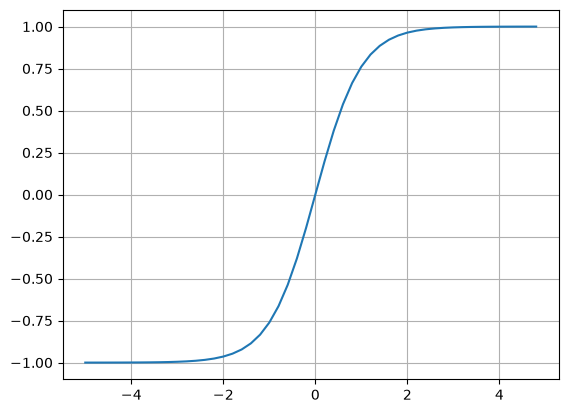

In [58]:
plt.plot(np.arange(-5,5,0.2),np.tanh(np.arange(-5,5,0.2)));plt.grid();

#### Now lets build a simple neural network

In [71]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.7, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'



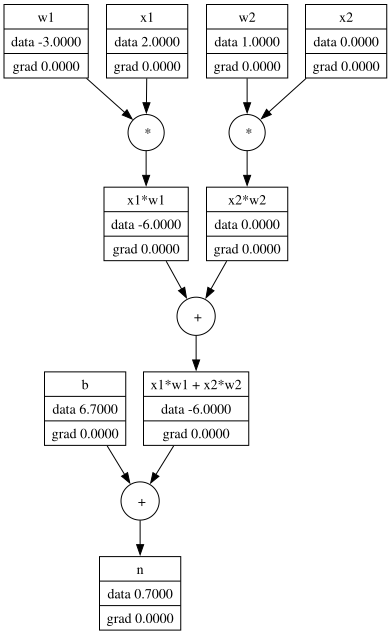

In [72]:
draw_dot(n)

#### The next step is to add the activation function to n, however we havent defined it, so we make a new function inside the class value to perform the tanh activation 

#### Ref img for tanh: https://github.com/MariyaJoseChirathalakkel/learning-notes/blob/main/assets/tanh_ref_img.png

In [73]:
class Value:
    def __init__(self,data, _children=(), _op='', label = ''):
        self.data = data
        self.grad = 0.0 # this will store the gradient of the Value object. In the initialisation we assume that every value will not impact the final output.
        self._prev = set(_children) # this will store the children of the Value object.
        self._op = _op # this will store the operation that was used to create the Value object.
        self.label = label # this will store the label for the Value object.

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op=' +')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op=' *')
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,),'tanh')
        return out


In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.7, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'


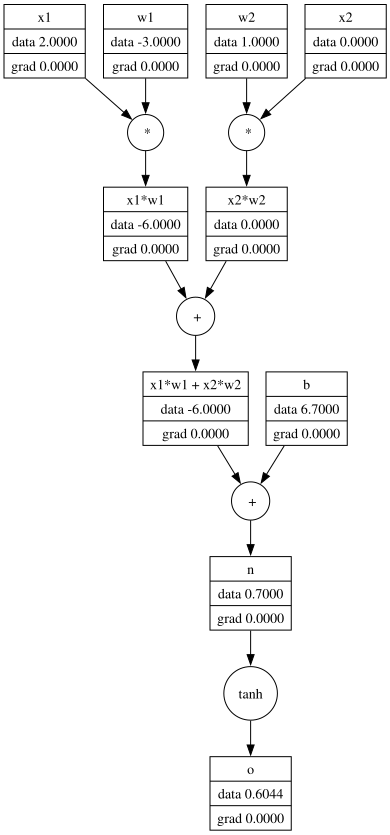

In [75]:
draw_dot(o)

#### The activation function is used to squash the output from the neuron and the output of tanh will go as a straight line after -1 and 1
#### As a next step we can try to change the bias and se what chnages is happenig to the output 


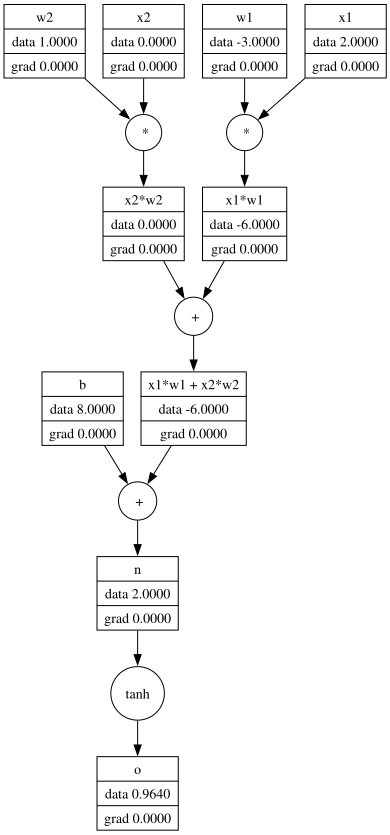

In [77]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(8.0, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

draw_dot(o)


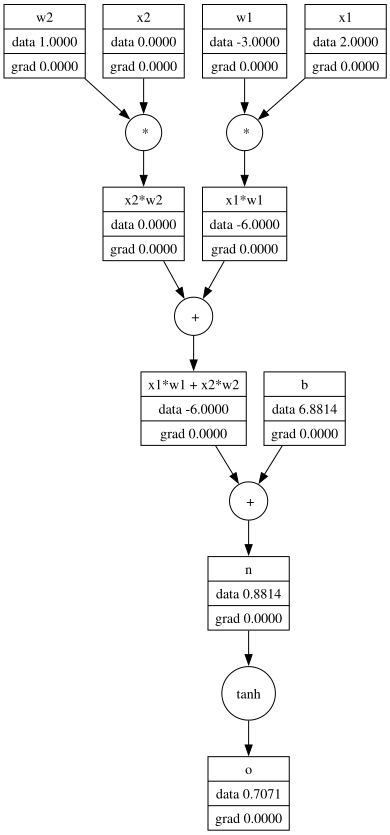

In [78]:
# change the bias again (just to get good values when doing backpropagation)


# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# forward pass of the neuron 
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'


x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# n is the output of the neuron which is the sum of the weighted inputs and the bias. This is the input to the activation function.
n= x1w1x2w2 + b; n.label='n'


# now we can add the activation function to n 

o = n.tanh(); o.label='o'

draw_dot(o)



### Now lets start with the backpropagation on the tiny neuron that we have creared 

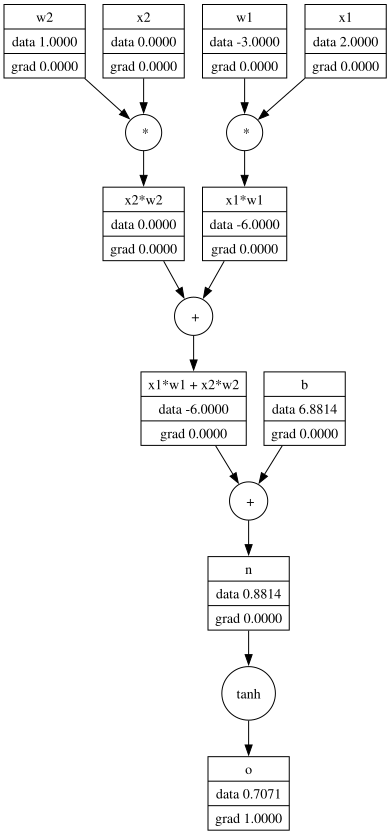

In [81]:
# To begin with, lets start from o and later find the derivative of o with respect to all the inputs in the neural network 
# so derivative of o with respect to o is 1.0 because the change in o with respect to o is 1.0. This is the base case for backpropagation.
o.grad = 1.0
draw_dot(o)
